# ZelaBairro: previsão de transbordo das lixeiras

Lucas Cortizo, RM 559734. Global Solution FIAP 2026.2, disciplina de IA & ML.

## 1. Problema

As lixeiras e caçambas do bairro transbordam antes da coleta. Eu quero prever, para cada lixeira, se ela vai transbordar nas próximas 24 horas.

É um problema de classificação com duas respostas: 1 (vai transbordar) ou 0 (não vai). A previsão é enviada para a API do projeto e aparece no app e no portal, para a subprefeitura saber onde mandar o caminhão primeiro.

In [1]:
import random
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import requests
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

## 2. Dataset simulado

Eu não tenho dados reais de lixeiras, então gerei 1.000 leituras com uma regra e um pouco de ruído. As colunas são:

- `dia_semana`: 0 (segunda) a 6 (domingo)
- `hora`: 0 a 23
- `tipo_local`: residencial, comercial ou feira
- `dia_de_feira`: 1 quando o local é de feira e o dia é quarta ou sábado
- `nivel_atual`: quanto a lixeira está cheia, de 0 a 100%
- `dias_desde_coleta`: 0 a 6

A regra soma pontos: o nível atual, mais 6 pontos por dia sem coleta, mais 10 se o local for comercial e mais 25 em dia de feira. Depois somo um ruído entre -10 e 10, porque na vida real nada é exato. Se der 100 pontos ou mais, `transborda_24h` vale 1.

A hora não entra na regra. Deixei ela no dataset para ver se o modelo percebe que ela não importa.

O `random.seed(42)` faz o sorteio sair sempre igual, então o resultado se repete toda vez que eu rodo.

In [2]:
random.seed(42)
TIPOS_LOCAL = ["residencial", "comercial", "feira"]

def calcular_dia_de_feira(tipo_local, dia_semana):
    # Feira livre simulada na quarta (2) e no sábado (5)
    if tipo_local == "feira" and dia_semana in (2, 5):
        return 1
    return 0

In [3]:
linhas = []
for _ in range(1000):
    dia_semana = random.randint(0, 6)
    hora = random.randint(0, 23)
    tipo_local = random.choice(TIPOS_LOCAL)
    dia_de_feira = calcular_dia_de_feira(tipo_local, dia_semana)
    nivel_atual = random.randint(0, 100)
    dias_desde_coleta = random.randint(0, 6)

    pontos = nivel_atual + 6 * dias_desde_coleta
    if tipo_local == "comercial":
        pontos += 10
    if dia_de_feira == 1:
        pontos += 25
    pontos += random.randint(-10, 10)
    transborda_24h = 1 if pontos >= 100 else 0

    linhas.append([dia_semana, hora, tipo_local, dia_de_feira,
                   nivel_atual, dias_desde_coleta, transborda_24h])

In [4]:
colunas = ["dia_semana", "hora", "tipo_local", "dia_de_feira",
           "nivel_atual", "dias_desde_coleta", "transborda_24h"]
df = pd.DataFrame(linhas, columns=colunas)
df.to_csv("dataset.csv", index=False)
df.head()

,dia_semana,hora,tipo_local,dia_de_feira,nivel_atual,dias_desde_coleta,transborda_24h
0,5,3,residencial,0,94,2,1
1,1,4,feira,0,13,5,0
2,0,18,comercial,0,4,0,0
3,1,7,feira,0,77,0,0
4,1,22,feira,0,89,4,1


## 3. Análise com pandas

Primeiro as estatísticas de cada coluna (média, mínimo, máximo) e quantas leituras transbordam e quantas não.

In [5]:
df.describe()

,dia_semana,hora,dia_de_feira,nivel_atual,dias_desde_coleta,transborda_24h
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,2.992000,11.743000,0.085000,51.294000,3.082000,0.26400
std,1.992965,6.839278,0.279021,29.301709,2.010303,0.44102
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,1.000000,6.000000,0.000000,26.000000,1.000000,0.00000
50%,3.000000,12.000000,0.000000,51.000000,3.000000,0.00000
75%,5.000000,18.000000,0.000000,78.000000,5.000000,1.00000
max,6.000000,23.000000,1.000000,100.000000,6.000000,1.00000


In [6]:
df["transborda_24h"].value_counts()

transborda_24h
0    736
1    264
Name: count, dtype: int64

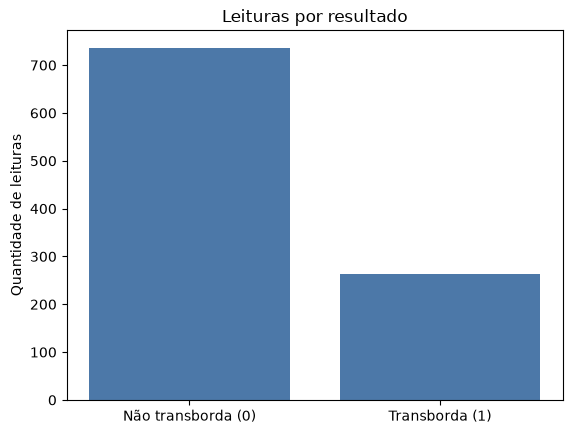

In [7]:
contagem = df["transborda_24h"].value_counts().sort_index()
plt.bar(["Não transborda (0)", "Transborda (1)"], contagem.values, color="#4C78A8")
plt.title("Leituras por resultado")
plt.ylabel("Quantidade de leituras")
plt.show()

No segundo gráfico eu separo o nível em faixas e vejo, em cada faixa, a porcentagem de leituras que transbordaram.

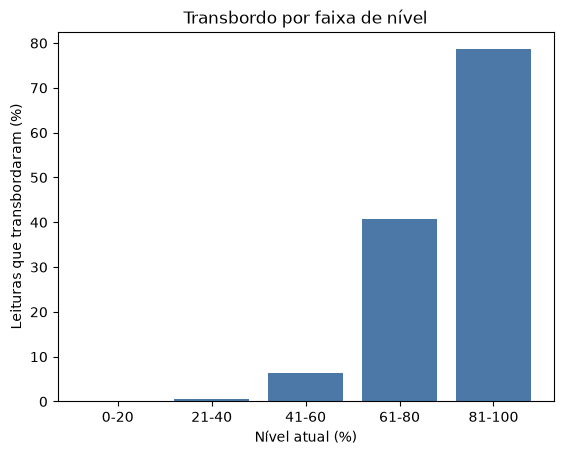

In [8]:
faixas = pd.cut(df["nivel_atual"], bins=[0, 20, 40, 60, 80, 100], include_lowest=True,
                labels=["0-20", "21-40", "41-60", "61-80", "81-100"])
taxa = df.groupby(faixas, observed=True)["transborda_24h"].mean() * 100

plt.bar(taxa.index.astype(str), taxa.values, color="#4C78A8")
plt.title("Transbordo por faixa de nível")
plt.xlabel("Nível atual (%)")
plt.ylabel("Leituras que transbordaram (%)")
plt.show()

Quanto mais cheia a lixeira está, maior a chance de transbordar, como a regra manda. Abaixo de 40% quase nenhuma transborda.

## 4. Preparação

A árvore de decisão só trabalha com números, então troquei `tipo_local` por 0, 1 e 2 com um dicionário. Faço isso numa cópia (`dados`) para a célula poder rodar de novo sem estragar o `df`.

Depois separo 80% das linhas para treino e 20% para teste. O teste fica guardado e só é usado na avaliação. O `stratify=y` mantém a mesma proporção de 0 e 1 nas duas partes.

In [9]:
MAPA_TIPO_LOCAL = {"residencial": 0, "comercial": 1, "feira": 2}

dados = df.copy()
dados["tipo_local"] = dados["tipo_local"].map(MAPA_TIPO_LOCAL)

X = dados.drop(columns=["transborda_24h"])
y = dados["transborda_24h"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(len(X_treino), "linhas de treino e", len(X_teste), "linhas de teste")

800 linhas de treino e 200 linhas de teste


## 5. Treino

O `DecisionTreeClassifier` aprende uma sequência de perguntas, por exemplo "o nível é maior que 70?". O `max_depth=5` limita a árvore a 5 níveis de perguntas. Sem limite ela decora o treino, até o ruído, e erra mais com dados novos.

In [10]:
modelo = DecisionTreeClassifier(max_depth=5, random_state=42)
modelo.fit(X_treino, y_treino)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

A importância mostra o quanto cada coluna ajudou nas decisões da árvore. Somando todas dá 1.

In [11]:
importancia = pd.Series(modelo.feature_importances_, index=X.columns)
importancia.sort_values(ascending=False)

nivel_atual          0.694733
dias_desde_coleta    0.202202
dia_de_feira         0.052301
tipo_local           0.034023
dia_semana           0.010898
hora                 0.005843
dtype: float64

O nível atual e os dias desde a coleta foram as colunas mais usadas, como na regra. A hora ficou perto de zero, então o modelo percebeu que ela não faz diferença.

## 6. Avaliação

A acurácia é a porcentagem de acertos nas linhas de teste, que o modelo nunca viu.

In [12]:
previsoes_teste = modelo.predict(X_teste)
acuracia = accuracy_score(y_teste, previsoes_teste)
print(f"Acurácia: {acuracia:.2%}")

Acurácia: 91.50%


A matriz de confusão mostra onde estão os acertos e os erros. As linhas são o que aconteceu de verdade e as colunas são o que o modelo previu.

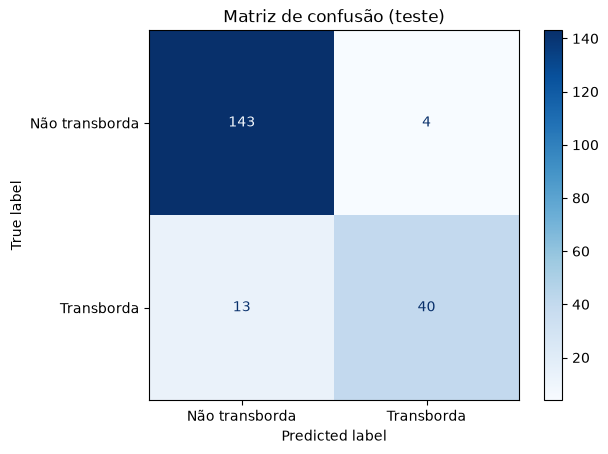

Acertou que não transborda: 143
Acertou que transborda: 40
Alarme falso (previu transbordo e não aconteceu): 4
Transbordo que o modelo não previu: 13


In [13]:
matriz = confusion_matrix(y_teste, previsoes_teste)
ConfusionMatrixDisplay(matriz, display_labels=["Não transborda", "Transborda"]).plot(cmap="Blues")
plt.title("Matriz de confusão (teste)")
plt.show()

vn, fp, fn, vp = matriz.ravel()
print("Acertou que não transborda:", vn)
print("Acertou que transborda:", vp)
print("Alarme falso (previu transbordo e não aconteceu):", fp)
print("Transbordo que o modelo não previu:", fn)

O modelo acertou 91,5% das 200 linhas de teste. Para comparar: só 26% das leituras do dataset transbordam, então um modelo que respondesse sempre "não transborda" já acertaria cerca de 74%. A árvore ficou bem acima disso.

Dos 53 transbordos do teste, o modelo previu 40 e deixou passar 13. Esse é o erro mais grave, porque a lixeira transborda sem aviso. Os 4 alarmes falsos só fazem o caminhão passar antes da hora.

Os erros vêm do ruído que eu coloquei na regra. Perto dos 100 pontos, leituras parecidas às vezes transbordam e às vezes não, e nenhum modelo acerta isso sempre.

## 7. Salvar o modelo

O `joblib` grava o modelo treinado num arquivo. Assim eu não preciso treinar de novo toda vez: é só carregar o `modelo.pkl`.

In [14]:
joblib.dump(modelo, "modelo.pkl")
print("Modelo salvo em modelo.pkl")

Modelo salvo em modelo.pkl


## 8. Integração com a API

Aqui o modelo entra na solução. A API precisa estar rodando em `localhost:8080`.

Busco as lixeiras ativas em `GET /lixeiras`, monto as mesmas colunas do treino para cada uma e envio a previsão para `POST /previsoes`. O app e o portal leem essa previsão depois.

De onde vem cada coluna:

- `nivel_atual`: o `nivelAtual` da lixeira, que o ESP32 atualiza pelo Node-RED
- `dia_semana` e `hora`: o relógio do computador
- `tipo_local` e `dias_desde_coleta`: a API não guarda essas informações, então usei valores fixos (residencial e 2 dias)

In [15]:
API_URL = "http://localhost:8080"
TIPO_LOCAL_PADRAO = "residencial"
DIAS_DESDE_COLETA_PADRAO = 2

resposta = requests.get(f"{API_URL}/lixeiras", params={"size": 100})
lixeiras = resposta.json()["content"]
print(len(lixeiras), "lixeiras ativas")

2 lixeiras ativas


O `predict_proba` devolve a chance de cada resposta. A posição 1 é a chance de transbordar, que vai no campo `probabilidade`. O `bool()` e o `float()` convertem os valores do scikit-learn para tipos comuns do Python, que o `requests` consegue mandar em JSON.

In [16]:
modelo_carregado = joblib.load("modelo.pkl")
agora = pd.Timestamp.now()

for lixeira in lixeiras:
    entrada = pd.DataFrame([{
        "dia_semana": agora.dayofweek,
        "hora": agora.hour,
        "tipo_local": MAPA_TIPO_LOCAL[TIPO_LOCAL_PADRAO],
        "dia_de_feira": calcular_dia_de_feira(TIPO_LOCAL_PADRAO, agora.dayofweek),
        "nivel_atual": lixeira["nivelAtual"],
        "dias_desde_coleta": DIAS_DESDE_COLETA_PADRAO,
    }])
    transborda = modelo_carregado.predict(entrada)[0]
    probabilidade = modelo_carregado.predict_proba(entrada)[0][1]

    previsao = {
        "lixeiraId": lixeira["id"],
        "transbordaEm24h": bool(transborda),
        "probabilidade": round(float(probabilidade), 2),
    }
    resposta = requests.post(f"{API_URL}/previsoes", json=previsao)
    print(lixeira["codigo"], "nível", lixeira["nivelAtual"], "->",
          resposta.status_code, resposta.json())

LX-002 nível 90 -> 201 {'dataHora': '2026-11-17T09:34:04.4685169', 'id': 2, 'lixeiraId': 2, 'probabilidade': 0.91, 'transbordaEm24h': True}
LX-003 nível 0 -> 201 {'dataHora': '2026-11-17T09:34:04.4815174', 'id': 3, 'lixeiraId': 3, 'probabilidade': 0.0, 'transbordaEm24h': False}


C:\Users\KABUM\AppData\Local\Temp\ipykernel_37112\1049939854.py:6: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dia_semana": agora.dayofweek,
C:\Users\KABUM\AppData\Local\Temp\ipykernel_37112\1049939854.py:9: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dia_de_feira": calcular_dia_de_feira(TIPO_LOCAL_PADRAO, agora.dayofweek),
C:\Users\KABUM\AppData\Local\Temp\ipykernel_37112\1049939854.py:6: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dia_semana": agora.dayofweek,
C:\Users\KABUM\AppData\Local\Temp\ipykernel_37112\1049939854.py:9: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dia_de_feira": calcular_dia_de_feira(TIPO_LOCAL_PADRAO, agora.dayofweek),
